# Download the PlantDoc classification dataset

In [1]:
!git clone --depth 1 https://github.com/pratikkayal/PlantDoc-Dataset.git /content/PlantDoc

Cloning into '/content/PlantDoc'...
remote: Enumerating objects: 2628, done.
remote: Counting objects: 100% (2628/2628), done.
remote: Compressing objects: 100% (2627/2627), done.
remote: Total 2628 (delta 1), reused 2616 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (2628/2628), 932.91 MiB | 18.58 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Updating files: 100% (2581/2581), done.


# Check that both PlantDoc splits are available

In [2]:
from pathlib import Path

plantdoc_path = Path("/content/PlantDoc")
splits = ("train", "test")

for split in splits:
    folder = plantdoc_path / split
    if not folder.is_dir():
        raise FileNotFoundError(f"Missing folder: {folder}")

print("PlantDoc train and test folders found.")

PlantDoc train and test folders found.


# Count image files in each class folder for each split

In [3]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_counts = {}

for split in splits:
    class_counts[split] = {}

    for folder in (plantdoc_path / split).iterdir():
        if not folder.is_dir() or folder.name.startswith("."):
            continue

        count = 0
        for file in folder.iterdir():
            if file.is_file() and file.suffix.lower() in image_extensions:
                count += 1

        class_counts[split][folder.name] = count

# Put the train and test counts side by side for each class

In [4]:
import pandas as pd

plantdoc_counts = pd.DataFrame(class_counts)
plantdoc_counts = plantdoc_counts.fillna(0).astype(int).sort_index()
plantdoc_counts.index.name = "PlantDoc class"

display(plantdoc_counts)

,train,test
PlantDoc class,,
Apple Scab Leaf,83,10
Apple leaf,82,9
Apple rust leaf,79,10
Bell_pepper leaf,53,8
Bell_pepper leaf spot,62,9
Blueberry leaf,106,11
Cherry leaf,47,10
Corn Gray leaf spot,64,4
Corn leaf blight,180,12


# Check the split totals and flag classes with no test images

In [5]:
print("Train image files:", plantdoc_counts["train"].sum())
print("Test image files:", plantdoc_counts["test"].sum())
print("Unique folder labels:", len(plantdoc_counts))

no_test_images = plantdoc_counts[plantdoc_counts["test"] == 0]
display(no_test_images)

Train image files: 2342
Test image files: 236
Unique folder labels: 28


,train,test
PlantDoc class,,
Tomato two spotted spider mites leaf,2,0


## **Step 2 — Inspect PlantVillage labels**

# Install the library used to load PlantVillage

In [6]:
%pip install -q datasets

# Download the file lists for the original color train and test splits

In [7]:
from pathlib import Path
from huggingface_hub import hf_hub_download

color_lists = {}

for split in ("train", "test"):
    file_path = hf_hub_download(
        repo_id="mohanty/PlantVillage",
        repo_type="dataset",
        filename=f"splits/color_{split}.txt",
    )
    color_lists[split] = Path(file_path).read_text().splitlines()

color_train.txt:   0%|          | 0.00/4.15M [00:00<?, ?B/s]

color_test.txt:   0%|          | 0.00/1.02M [00:00<?, ?B/s]

# Remove blank lines and count the listed images in each split

In [8]:
for split, lines in color_lists.items():
    color_lists[split] = [line.strip() for line in lines if line.strip()]
    print(f"{split}: {len(color_lists[split]):,} listed images")

train: 43,596 listed images
test: 10,709 listed images


# Read each class name from the folder that contains the image

In [9]:
plantvillage_labels = sorted({
    Path(image_path).parent.name
    for image_path in color_lists["train"]
})

print("Number of PlantVillage labels:", len(plantvillage_labels))
for class_name in plantvillage_labels:
    print(class_name)

Number of PlantVillage labels: 38
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Blueberry___healthy
Cherry_(including_sour)___Powdery_mildew
Cherry_(including_sour)___healthy
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Corn_(maize)___Common_rust_
Corn_(maize)___Northern_Leaf_Blight
Corn_(maize)___healthy
Grape___Black_rot
Grape___Esca_(Black_Measles)
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Grape___healthy
Orange___Haunglongbing_(Citrus_greening)
Peach___Bacterial_spot
Peach___healthy
Pepper,_bell___Bacterial_spot
Pepper,_bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Raspberry___healthy
Soybean___healthy
Squash___Powdery_mildew
Strawberry___Leaf_scorch
Strawberry___healthy
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mosaic_virus

## **Step 2B — Match PlantDoc and PlantVillage classes**

# Match PlantDoc folder names to their PlantVillage equivalents

In [10]:
class_map = {
    "Apple Scab Leaf": "Apple___Apple_scab",
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",
    "Squash Powdery mildew leaf": "Squash___Powdery_mildew",
    "grape leaf black rot": "Grape___Black_rot",
}

# Add tomato diseases with matching labels in both datasets

In [11]:
class_map.update({
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold",
})

# Count how many listed images each class has in each PlantVillage split

In [12]:
from collections import Counter

pv_counts = {}

for split, paths in color_lists.items():
    pv_counts[split] = Counter(Path(path).parent.name for path in paths)

# Check that each mapped class exists and has images in the required splits

In [13]:
assert len(set(class_map.values())) == len(class_map), "Duplicate PlantVillage label"

for doc_label, village_label in class_map.items():
    assert doc_label in plantdoc_counts.index, f"Missing PlantDoc label: {doc_label}"
    assert plantdoc_counts.loc[doc_label, "test"] > 0, f"No PlantDoc test files: {doc_label}"
    assert pv_counts["train"][village_label] > 0, f"No PlantVillage train entries: {village_label}"
    assert pv_counts["test"][village_label] > 0, f"No PlantVillage test entries: {village_label}"

print(f"All {len(class_map)} mappings passed the label and split checks.")

All 12 mappings passed the label and split checks.


# Show the paired labels and how many test examples each class has

In [14]:
mapping_table = pd.Series(class_map, name="PlantVillage class").to_frame()
mapping_table.index.name = "PlantDoc class"

mapping_table["PlantVillage test"] = mapping_table["PlantVillage class"].map(pv_counts["test"])
mapping_table["PlantDoc test"] = plantdoc_counts["test"]

display(mapping_table)
print("PlantDoc test files in the pilot:", mapping_table["PlantDoc test"].sum())

,PlantVillage class,PlantVillage test,PlantDoc test
PlantDoc class,,,
Apple Scab Leaf,Apple___Apple_scab,127,10
Corn Gray leaf spot,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,107,4
Potato leaf early blight,Potato___Early_blight,164,8
Potato leaf late blight,Potato___Late_blight,212,8
Squash Powdery mildew leaf,Squash___Powdery_mildew,378,6
grape leaf black rot,Grape___Black_rot,168,8
Tomato Early blight leaf,Tomato___Early_blight,215,9
Tomato Septoria leaf spot,Tomato___Septoria_leaf_spot,337,11
Tomato leaf bacterial spot,Tomato___Bacterial_spot,436,9


PlantDoc test files in the pilot: 99


# Download the image archive from the same repo as the split lists

In [15]:
archive_path = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    repo_type="dataset",
    filename="data.zip",
)

print("PlantVillage archive downloaded.")

data.zip:   0%|          | 0.00/2.18G [00:00<?, ?B/s]

PlantVillage archive downloaded.


# Keep the original split and select only the mapped disease classes

In [16]:
pilot_classes = set(class_map.values())
pilot_paths = {}

for split, paths in color_lists.items():
    pilot_paths[split] = [
        path for path in paths if Path(path).parent.name in pilot_classes
    ]
    print(f"PlantVillage {split}: {len(pilot_paths[split]):,} pilot images")

PlantVillage train: 11,533 pilot images
PlantVillage test: 2,757 pilot images


# Match each split-list path to its image inside the ZIP

In [17]:
from zipfile import ZipFile

pv_image_root = Path("/content/PlantVillage_pilot")

with ZipFile(archive_path) as archive:
    color_members = {}
    for member in archive.namelist():
        if "raw/color/" in member and not member.endswith("/"):
            relative_path = member[member.index("raw/color/"):]
            color_members[relative_path] = member

    for split, paths in pilot_paths.items():
        for path in paths:
            relative_path = path.removeprefix("./")
            member = color_members[relative_path]
            target = pv_image_root / split / relative_path
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(archive.read(member))

print("Pilot images extracted into separate train and test folders.")

Pilot images extracted into separate train and test folders.


# Open each image and record a hash to detect byte-identical files

In [18]:
from collections import defaultdict
from hashlib import sha256
from PIL import Image

def audit_images(paths):
    hashes = defaultdict(list)
    unreadable = []

    for path in paths:
        try:
            with Image.open(path) as image:
                image.load()
            fingerprint = sha256(path.read_bytes()).hexdigest()
            hashes[fingerprint].append(path)
        except (OSError, ValueError):
            unreadable.append(path)

    return hashes, unreadable

# Audit the source train/test images and the mapped PlantDoc test images

In [19]:
audit_paths = {
    "PlantVillage train": [pv_image_root / "train" / p for p in pilot_paths["train"]],
    "PlantVillage test": [pv_image_root / "test" / p for p in pilot_paths["test"]],
    "PlantDoc test": [
        path
        for label in class_map
        for path in (plantdoc_path / "test" / label).iterdir()
        if path.is_file() and path.suffix.lower() in image_extensions
    ],
}

image_audits = {}
for name, paths in audit_paths.items():
    hashes, unreadable = audit_images(paths)
    image_audits[name] = hashes, unreadable
    print(f"{name}: {len(paths):,} files, {len(unreadable)} unreadable")

PlantVillage train: 11,533 files, 0 unreadable
PlantVillage test: 2,757 files, 0 unreadable
PlantDoc test: 99 files, 0 unreadable


# Check whether a test image is byte-identical to a training image

In [20]:
train_hashes = image_audits["PlantVillage train"][0]

for test_name in ("PlantVillage test", "PlantDoc test"):
    test_hashes = image_audits[test_name][0]
    shared_hashes = train_hashes.keys() & test_hashes.keys()
    print(f"{test_name}: {len(shared_hashes)} unique hashes shared with train")

PlantVillage test: 3 unique hashes shared with train
PlantDoc test: 0 unique hashes shared with train


# Keep both test sets fixed and exclude matching files from training

In [21]:
source_hashes = image_audits["PlantVillage train"][0]
lab_test_hashes = set(image_audits["PlantVillage test"][0])
field_test_hashes = set(image_audits["PlantDoc test"][0])
test_hashes = lab_test_hashes | field_test_hashes

clean_source_hashes = {
    fingerprint: paths
    for fingerprint, paths in source_hashes.items()
    if fingerprint not in test_hashes
}

clean_count = sum(len(paths) for paths in clean_source_hashes.values())
print("Training files excluded:", len(audit_paths["PlantVillage train"]) - clean_count)
print("Training files remaining:", clean_count)
assert not (clean_source_hashes.keys() & test_hashes)

Training files excluded: 3
Training files remaining: 11530


# Keep one copy per hash so duplicates cannot cross into validation

In [22]:
source_rows = []

for fingerprint, paths in sorted(clean_source_hashes.items()):
    labels = {path.parent.name for path in paths}
    if len(labels) != 1:
        raise ValueError(f"Identical image has conflicting labels: {paths}")

    source_rows.append({
        "path": min(paths),
        "label": labels.pop(),
        "hash": fingerprint,
    })

source_data = pd.DataFrame(source_rows)
print("Extra copies excluded:", clean_count - len(source_data))
print("Unique source images:", len(source_data))

Extra copies excluded: 5
Unique source images: 11525


# Use 15% of the cleaned source pool for validation

In [23]:
from sklearn.model_selection import train_test_split

train_data, val_data = train_test_split(
    source_data,
    test_size=0.15,
    random_state=42,
    stratify=source_data["label"],
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))

Training images: 9796
Validation images: 1729


# Verify class coverage and check for exact overlap between splits

In [24]:
expected_labels = set(class_map.values())

assert set(train_data["label"]) == expected_labels
assert set(val_data["label"]) == expected_labels
assert set(train_data["hash"]).isdisjoint(val_data["hash"])
assert set(source_data["hash"]).isdisjoint(test_hashes)

split_counts = pd.DataFrame({
    "Train": train_data["label"].value_counts(),
    "Validation": val_data["label"].value_counts(),
}).sort_index()

display(split_counts)

,Train,Validation
label,,
Apple___Apple_scab,428,75
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,345,61
Grape___Black_rot,860,152
Potato___Early_blight,711,125
Potato___Late_blight,670,118
Squash___Powdery_mildew,1238,219
Tomato___Bacterial_spot,1437,254
Tomato___Early_blight,667,118
Tomato___Late_blight,1297,229


# Use one class order for training, validation, and both test sets

In [25]:
import torch
from torchvision.models import resnet18, ResNet18_Weights

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class_names = sorted(class_map.values())
label_to_id = {label: index for index, label in enumerate(class_names)}

print("Device:", device)
print("Number of classes:", len(class_names))

Device: cpu
Number of classes: 12


# Load one image at a time and apply the pretrained model's preprocessing

In [26]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader

weights = ResNet18_Weights.DEFAULT
preprocess = weights.transforms()

class LeafDataset(Dataset):
    def __init__(self, rows):
        self.samples = list(zip(rows["path"], rows["label"]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        with Image.open(path) as image:
            pixels = preprocess(image.convert("RGB"))
        return pixels, label_to_id[label]

# Shuffle training batches and keep validation in a fixed order

In [27]:
train_loader = DataLoader(LeafDataset(train_data), batch_size=32, shuffle=True)
val_loader = DataLoader(LeafDataset(val_data), batch_size=32)

images, labels = next(iter(train_loader))
print("Image batch shape:", tuple(images.shape))
print("Label batch shape:", tuple(labels.shape))

Image batch shape: (32, 3, 224, 224)
Label batch shape: (32,)


# Freeze the pretrained backbone and train a new 12-class head

In [28]:
from torch import nn

model = resnet18(weights=weights)
model.requires_grad_(False)
model.fc = nn.Linear(model.fc.in_features, len(class_names))
model = model.to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 148MB/s]


# Update only the classifier and return the average training loss

In [29]:
def train_one_epoch():
  # Keep the frozen backbone's batch norm statistics fixed
    model.eval()
    model.fc.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()

        loss = loss_fn(model(images), labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)

    return total_loss / len(train_loader.dataset)

# Measure validation macro-F1 without updating model weights

In [30]:
from sklearn.metrics import f1_score

@torch.inference_mode()
def validation_f1():
    model.eval()
    actual, predicted = [], []

    for images, labels in val_loader:
        predictions = model(images.to(device)).argmax(dim=1)
        actual.extend(labels.tolist())
        predicted.extend(predictions.cpu().tolist())

    return f1_score(actual, predicted, average="macro", zero_division=0)

# Save the checkpoint with the highest validation macro-F1

In [31]:
best_f1 = -1.0
checkpoint_path = "/content/resnet18_baseline.pt"

for epoch in range(1, 4):
    train_loss = train_one_epoch()
    val_f1 = validation_f1()
    print(f"Epoch {epoch} | Train loss {train_loss:.4f} | Val macro-F1 {val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save({
            "model_state": model.state_dict(),
            "class_names": class_names,
            "epoch": epoch,
            "val_macro_f1": val_f1,
        }, checkpoint_path)

print(f"Best validation macro-F1: {best_f1:.4f}")

Epoch 1 | Train loss 0.7818 | Val macro-F1 0.8659
Epoch 2 | Train loss 0.3228 | Val macro-F1 0.9037
Epoch 3 | Train loss 0.2458 | Val macro-F1 0.9241
Best validation macro-F1: 0.9241


# Load the checkpoint created by our own training cell

In [32]:
assert Path(checkpoint_path).is_file(), "Finish Step 5 before running this cell."

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False,
)

assert checkpoint["class_names"] == class_names, "Class order mismatch"
model.load_state_dict(checkpoint["model_state"])
model.eval()

print("Best epoch:", checkpoint["epoch"])
print(f"Validation macro-F1: {checkpoint['val_macro_f1']:.4f}")

Best epoch: 3
Validation macro-F1: 0.9241


# Translate PlantDoc folder labels into the same labels used in training

In [33]:
test_frames = {}

for name in ("PlantVillage test", "PlantDoc test"):
    paths = sorted(audit_paths[name])
    labels = [path.parent.name for path in paths]

    if name == "PlantDoc test":
        labels = [class_map[label] for label in labels]

    assert set(labels) == set(class_names)
    test_frames[name] = pd.DataFrame({"path": paths, "label": labels})
    print(name, len(paths))

PlantVillage test 2757
PlantDoc test 99


# Run inference without updating the model weights

In [34]:
@torch.inference_mode()
def predict_test(rows):
    loader = DataLoader(LeafDataset(rows), batch_size=32)
    actual, predicted = [], []

    for images, labels in loader:
        logits = model(images.to(device))
        actual.extend(labels.tolist())
        predicted.extend(logits.argmax(dim=1).cpu().tolist())

    return actual, predicted

test_predictions = {}

for name, rows in test_frames.items():
    print("Evaluating", name, flush=True)
    test_predictions[name] = predict_test(rows)
    print("Finished", name, flush=True)

Evaluating PlantVillage test
Finished PlantVillage test
Evaluating PlantDoc test
Finished PlantDoc test


# Compare the same model on the same 12 classes in both domains

In [35]:
from sklearn.metrics import accuracy_score

class_ids = list(range(len(class_names)))
score_rows = []

for name, (actual, predicted) in test_predictions.items():
    score_rows.append({
        "Test set": name,
        "Images": len(actual),
        "Accuracy (%)": 100 * accuracy_score(actual, predicted),
        "Macro-F1 (%)": 100 * f1_score(
            actual, predicted, labels=class_ids, average="macro", zero_division=0
        ),
    })

scores = pd.DataFrame(score_rows).set_index("Test set")
gap = scores.loc["PlantVillage test", "Macro-F1 (%)"] - scores.loc["PlantDoc test", "Macro-F1 (%)"]

display(scores.round(2))
print(f"Macro-F1 gap (PlantVillage minus PlantDoc): {gap:.2f} percentage points")

,Images,Accuracy (%),Macro-F1 (%)
Test set,,,
PlantVillage test,2757,92.46,92.08
PlantDoc test,99,33.33,34.89


Macro-F1 gap (PlantVillage minus PlantDoc): 57.19 percentage points


# Include support so each score can be read with its test sample count

In [36]:
from sklearn.metrics import precision_recall_fscore_support

field_actual, field_predicted = test_predictions["PlantDoc test"]

precision, recall, f1, support = precision_recall_fscore_support(
    field_actual, field_predicted, labels=class_ids, zero_division=0
)

field_results = pd.DataFrame({
    "Class": class_names,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Test images": support,
})

display(field_results.sort_values("F1").round(3))

,Class,Precision,Recall,F1,Test images
6,Tomato___Bacterial_spot,0.000,0.000,0.000,9
9,Tomato___Leaf_Mold,0.000,0.000,0.000,6
11,Tomato___Tomato_mosaic_virus,0.000,0.000,0.000,10
3,Potato___Early_blight,0.143,0.125,0.133,8
4,Potato___Late_blight,0.500,0.125,0.200,8
10,Tomato___Septoria_leaf_spot,0.333,0.182,0.235,11
8,Tomato___Late_blight,0.172,1.000,0.294,10
0,Apple___Apple_scab,1.000,0.200,0.333,10
7,Tomato___Early_blight,0.333,0.333,0.333,9
5,Squash___Powdery_mildew,1.000,0.667,0.800,6


# Use short labels so the confusion matrix fits in the report

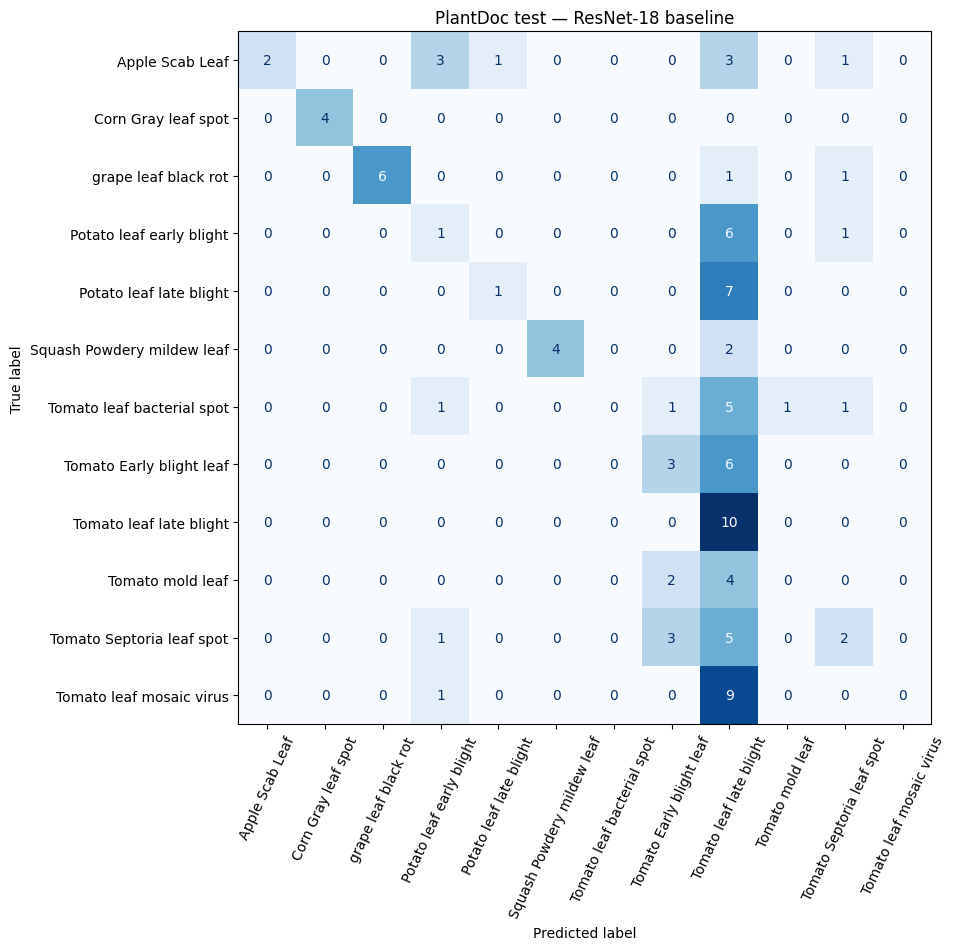

In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

doc_label_by_class = {village: doc for doc, village in class_map.items()}
display_labels = [doc_label_by_class[name] for name in class_names]

fig, ax = plt.subplots(figsize=(12, 9))
ConfusionMatrixDisplay.from_predictions(
    field_actual, field_predicted, labels=class_ids,
    display_labels=display_labels, xticks_rotation=65,
    cmap="Blues", colorbar=False, ax=ax,
)

ax.set_title("PlantDoc test — ResNet-18 baseline")
fig.savefig("/content/plantdoc_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

# Save the tables for the group report

In [38]:
scores.round(2).to_csv("/content/baseline_test_scores.csv")
field_results.round(4).to_csv("/content/plantdoc_per_class.csv", index=False)

print("Results tables saved in /content.")

Results tables saved in /content.
